# Invoice late-payment prediction

**Goal:** predict whether an invoice will be paid after its due date (`late = 1`) or on time (`late = 0`).

**Data:** Kaggle *Payment Date Dataset* (`rajattomar132/payment-date-dataset`): 50,000 invoices from 2019-2020 with customer, amount, payment terms, posting date, due date and payment date.

**Notebook map**

1. Download and clean the dataset
   - 1.1 Setup and download
   - 1.2 Clean the data
   - 1.3 Convert the dates
   - 1.4 Build the target `late`
   - 1.5 Feature engineering
   - 1.6 Train / validation / test split
2. Logistic regression
   - 2.1 Baseline
   - 2.2 Which features help?
   - 2.3 Random vs time-based split
   - 2.4 Result
3. Random forest
   - 3.1 Matrices for the tree models
   - 3.2 Decision tree
   - 3.3 Decision tree tuning
   - 3.4 Random forest
   - 3.5 Random forest tuning
   - 3.6 Result
4. XGBoost
   - 4.1 First model
   - 4.2 Tuning (`eta`, `max_depth`, `min_child_weight`)
   - 4.3 Result
5. Final test
   - 5.1 Comparison of the three models
   - 5.2 Final model

> Run it from the top (**Kernel > Restart & Run All**). Sections 3.5 and 4 take a few minutes.

## 1. Download and clean the dataset

### 1.1 Setup and download

Library versions used in this notebook. Keep them for `requirements.txt` and for the Docker image, because the final model is saved with `pickle` and must be loaded with the same versions.

`kagglehub` downloads the dataset from Kaggle (needs internet). The file has 50,000 rows and 19 columns.

In [1]:
import  sklearn as skl
import  pandas as pd
import  numpy as np
import  xgboost as xgb

for lib in (skl, pd, np, xgb):
    print(lib.__name__, lib.__version__)

sklearn 1.7.2
pandas 2.3.3
numpy 2.3.5
xgboost 3.4.1


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download('rajattomar132/payment-date-dataset')

In [3]:
print(path + '/dataset.csv')

/home/orlando/.cache/kagglehub/datasets/rajattomar132/payment-date-dataset/versions/2/dataset.csv


In [4]:
data = path + '/dataset.csv'
df = pd.read_csv(data)
len(df)

50000

### 1.2 Clean the data

- Column names to lowercase, text values to lowercase with `_` instead of spaces.
- Quick inspection: `clear_date` is empty for the open invoices, `area_business` is empty in every row, `document_type` is almost always `rv`.
- **Duplicates:** the same invoice appears more than once with identical values in every column. The repeated rows are removed (keeping the first), so a copy cannot end up in both training and validation.
- **Useless columns removed:** `document_create_date.1` (near-copy of `document_create_date`), `area_business` (empty), `document_type` (almost constant), `invoice_id` (identifier, with nulls) and `posting_id` (always 1).

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.head().T

,0,1,2,3,4
business_code,U001,U001,U001,CA02,U001
cust_number,200769623,200980828,200792734,140105686,200769623
name_customer,WAL-MAR corp,BEN E,MDV/ trust,SYSC llc,WAL-MAR foundation
clear_date,2/11/2020 0:00,8/8/2019 0:00,12/30/2019 0:00,NaN,11/25/2019 0:00
buisness_year,2020,2019,2019,2020,2019
doc_id,1930438491,1929646410,1929873765,2960623488,1930147974
posting_date,1/26/2020,7/22/2019,9/14/2019,3/30/2020,11/13/2019
document_create_date,20200125,20190722,20190914,20200330,20191113
document_create_date.1,20200126,20190722,20190914,20200330,20191113
due_in_date,20200210,20190811,20190929,20200410,20191128


In [6]:
df.dtypes

business_code              object
cust_number                object
name_customer              object
clear_date                 object
buisness_year               int64
doc_id                      int64
posting_date               object
document_create_date        int64
document_create_date.1      int64
due_in_date                 int64
invoice_currency           object
document_type              object
posting_id                  int64
area_business             float64
total_open_amount         float64
baseline_create_date        int64
cust_payment_terms         object
invoice_id                float64
isopen                      int64
dtype: object

In [7]:
categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [8]:
df.head(8).T

,0,1,2,3,4,5,6,7
business_code,u001,u001,u001,ca02,u001,ca02,u001,u001
cust_number,200769623,200980828,200792734,140105686,200769623,140106181,200769623,200744019
name_customer,wal-mar_corp,ben_e_,mdv/_trust,sysc_llc,wal-mar_foundation,the__corporation,wal-mar_in,targ_us
clear_date,2/11/2020_0:00,8/8/2019_0:00,12/30/2019_0:00,NaN,11/25/2019_0:00,12/4/2019_0:00,11/12/2019_0:00,NaN
buisness_year,2020,2019,2019,2020,2019,2019,2019,2020
doc_id,1930438491,1929646410,1929873765,2960623488,1930147974,2960581231,1930083373,1930659387
posting_date,1/26/2020,7/22/2019,9/14/2019,3/30/2020,11/13/2019,9/20/2019,11/1/2019,3/19/2020
document_create_date,20200125,20190722,20190914,20200330,20191113,20190920,20191031,20200318
document_create_date.1,20200126,20190722,20190914,20200330,20191113,20190920,20191101,20200319
due_in_date,20200210,20190811,20190929,20200410,20191128,20191004,20191116,20200403


In [9]:
df.isnull().sum()

business_code                 0
cust_number                   0
name_customer                 0
clear_date                10000
buisness_year                 0
doc_id                        0
posting_date                  0
document_create_date          0
document_create_date.1        0
due_in_date                   0
invoice_currency              0
document_type                 0
posting_id                    0
area_business             50000
total_open_amount             0
baseline_create_date          0
cust_payment_terms            0
invoice_id                    6
isopen                        0
dtype: int64

In [10]:
df.document_type.value_counts()

document_type
rv    49994
x2        6
Name: count, dtype: int64

In [11]:
# Duplicated rows:

key = ["business_code", "buisness_year", "doc_id"]
print(df.duplicated().sum())                              # identical in every column (but check invoice_id if you already dropped it)
dups = df[df.duplicated(subset=key, keep=False)].sort_values("doc_id")
dups.head(6)

1161


,business_code,cust_number,name_customer,clear_date,buisness_year,doc_id,posting_date,document_create_date,document_create_date.1,due_in_date,invoice_currency,document_type,posting_id,area_business,total_open_amount,baseline_create_date,cust_payment_terms,invoice_id,isopen
37468,u001,200794332,cost_foundation,1/14/2019_0:00,2019,1928543057,12/31/2018,20181230,20181231,20190115,usd,rv,1,NaN,15798.14,20181231,naax,1.928543e+09,0
7057,u001,200794332,cost_foundation,1/14/2019_0:00,2019,1928543057,12/31/2018,20181230,20181231,20190115,usd,rv,1,NaN,15798.14,20181231,naax,1.928543e+09,0
45187,u001,200769623,wal-mar_systems,1/14/2019_0:00,2019,1928543373,12/31/2018,20181230,20181231,20190115,usd,rv,1,NaN,21168.64,20181231,nah4,1.928543e+09,0
49361,u001,200769623,wal-mar_systems,1/14/2019_0:00,2019,1928543373,12/31/2018,20181230,20181231,20190115,usd,rv,1,NaN,21168.64,20181231,nah4,1.928543e+09,0
47206,u001,200769623,wal-mar_in,1/14/2019_0:00,2019,1928545098,12/31/2018,20181231,20181231,20190115,usd,rv,1,NaN,43486.59,20181231,nah4,1.928545e+09,0
46651,u001,200769623,wal-mar_in,1/14/2019_0:00,2019,1928545098,12/31/2018,20181231,20181231,20190115,usd,rv,1,NaN,43486.59,20181231,nah4,1.928545e+09,0


In [12]:
# Drop identical rows:

df = df.drop_duplicates()
print(df.duplicated().sum()) 

0


In [13]:
# Drop some columns that are useless:

del(df['document_create_date.1'])
del(df['area_business'])
del(df['document_type'])
del(df['invoice_id'])      # identifier (copy of doc_id), has a few nulls
del(df['posting_id'])      # always 1

In [14]:
df.head().T

,0,1,2,3,4
business_code,u001,u001,u001,ca02,u001
cust_number,200769623,200980828,200792734,140105686,200769623
name_customer,wal-mar_corp,ben_e_,mdv/_trust,sysc_llc,wal-mar_foundation
clear_date,2/11/2020_0:00,8/8/2019_0:00,12/30/2019_0:00,NaN,11/25/2019_0:00
buisness_year,2020,2019,2019,2020,2019
doc_id,1930438491,1929646410,1929873765,2960623488,1930147974
posting_date,1/26/2020,7/22/2019,9/14/2019,3/30/2020,11/13/2019
document_create_date,20200125,20190722,20190914,20200330,20191113
due_in_date,20200210,20190811,20190929,20200410,20191128
invoice_currency,usd,usd,usd,cad,usd


### 1.3 Convert the dates

The dates come in two formats: `yyyymmdd` integers (due date, baseline date, creation date) and month/day/year text (`clear_date`, `posting_date`). `format_date` converts both to `datetime64`.

The `NaT` values in `clear_date` are expected: they are the open (still unpaid) invoices.

In [15]:
def format_date(s):
    # numbers (yyyymmdd): Int64 keeps NaN without turning the numbers into floats
    if pd.api.types.is_numeric_dtype(s):
        s = s.astype("Int64")

    # to text; drop the time part after "_" (e.g. "2/11/2020_0:00" -> "2/11/2020")
    s = s.astype("string").str.split("_").str[0]

    # which values look like yyyymmdd (8 digits)
    is_ymd = s.str.fullmatch(r"\d{8}").fillna(False).astype(bool)

    mdy = pd.to_datetime(s.mask(is_ymd),  format="%m/%d/%Y", errors="coerce")
    ymd = pd.to_datetime(s.where(is_ymd), format="%Y%m%d",   errors="coerce")
    return mdy.fillna(ymd)

In [16]:
date_cols = ['clear_date', 'posting_date', 'document_create_date',
             'due_in_date', 'baseline_create_date']

for c in date_cols:
    df[c] = format_date(df[c])

print(df[date_cols].dtypes)
print(df[date_cols].isna().sum())

/tmp/ipykernel_185011/3818965390.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  is_ymd = s.str.fullmatch(r"\d{8}").fillna(False).astype(bool)


clear_date              datetime64[ns]
posting_date            datetime64[ns]
document_create_date    datetime64[ns]
due_in_date             datetime64[ns]
baseline_create_date    datetime64[ns]
dtype: object
clear_date              9681
posting_date               0
document_create_date       0
due_in_date                0
baseline_create_date       0
dtype: int64


In [17]:
df.head().T

,0,1,2,3,4
business_code,u001,u001,u001,ca02,u001
cust_number,200769623,200980828,200792734,140105686,200769623
name_customer,wal-mar_corp,ben_e_,mdv/_trust,sysc_llc,wal-mar_foundation
clear_date,2020-02-11 00:00:00,2019-08-08 00:00:00,2019-12-30 00:00:00,NaT,2019-11-25 00:00:00
buisness_year,2020,2019,2019,2020,2019
doc_id,1930438491,1929646410,1929873765,2960623488,1930147974
posting_date,2020-01-26 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2020-03-30 00:00:00,2019-11-13 00:00:00
document_create_date,2020-01-25 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2020-03-30 00:00:00,2019-11-13 00:00:00
due_in_date,2020-02-10 00:00:00,2019-08-11 00:00:00,2019-09-29 00:00:00,2020-04-10 00:00:00,2019-11-28 00:00:00
invoice_currency,usd,usd,usd,cad,usd


### 1.4 Build the target `late`

Only **paid** invoices (`isopen == 0`) have a real answer: `late = 1` if `clear_date > due_in_date`, otherwise `0`.

**Why the open invoices are left out:** every open invoice was posted after Feb 27, 2020 and every paid invoice before that date. Paid invoices have payment dates as late as May 22, 2020, yet not one invoice posted after Feb 27 was paid. This is a clean cut in time (the payment date is simply not available for the newest invoices), so "open" here does not mean "late". Labeling them late would invent about 9,000 answers. They are kept in `df_open`: they are the invoices a deployed model would score.

`clear_date` and `isopen` are deleted afterwards because the target was built from them. If they stayed as inputs, the model would see the answer (leakage).

In [18]:
# Paid and open invoices: when were they posted?

print(df.isopen.value_counts())
print('paid invoices posted from', df[df.isopen == 0].posting_date.min().date(), 'to', df[df.isopen == 0].posting_date.max().date())
print('open invoices posted from', df[df.isopen == 1].posting_date.min().date(), 'to', df[df.isopen == 1].posting_date.max().date())
print('latest payment date:', df.clear_date.max().date())

isopen
0    39158
1     9681
Name: count, dtype: int64
paid invoices posted from 2018-12-30 to 2020-02-27
open invoices posted from 2020-02-27 to 2020-05-22
latest payment date: 2020-05-22


In [19]:
# Building the target. Only paid invoices have a real answer;
# the open ones are kept apart (df_open): they are what a deployed model would score.

df_open = df[df.isopen == 1].copy()
df = df[df.isopen == 0].copy()

df["late"] = (df.clear_date > df.due_in_date).astype(int)

In [20]:
print(len(df))
df.head().T

39158


,0,1,2,4,5
business_code,u001,u001,u001,u001,ca02
cust_number,200769623,200980828,200792734,200769623,140106181
name_customer,wal-mar_corp,ben_e_,mdv/_trust,wal-mar_foundation,the__corporation
clear_date,2020-02-11 00:00:00,2019-08-08 00:00:00,2019-12-30 00:00:00,2019-11-25 00:00:00,2019-12-04 00:00:00
buisness_year,2020,2019,2019,2019,2019
doc_id,1930438491,1929646410,1929873765,1930147974,2960581231
posting_date,2020-01-26 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2019-11-13 00:00:00,2019-09-20 00:00:00
document_create_date,2020-01-25 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2019-11-13 00:00:00,2019-09-20 00:00:00
due_in_date,2020-02-10 00:00:00,2019-08-11 00:00:00,2019-09-29 00:00:00,2019-11-28 00:00:00,2019-10-04 00:00:00
invoice_currency,usd,usd,usd,usd,cad


In [21]:
print (f"late: mean = {df.late.mean():.3f} and unique values = {df.late.unique()}")

late: mean = 0.419 and unique values = [1 0]


In [22]:
# clear_date and is_open have to be delete because "late" is created based in this information:

del(df['clear_date'])
del(df['isopen'])

In [23]:
df.head().T

,0,1,2,4,5
business_code,u001,u001,u001,u001,ca02
cust_number,200769623,200980828,200792734,200769623,140106181
name_customer,wal-mar_corp,ben_e_,mdv/_trust,wal-mar_foundation,the__corporation
buisness_year,2020,2019,2019,2019,2019
doc_id,1930438491,1929646410,1929873765,1930147974,2960581231
posting_date,2020-01-26 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2019-11-13 00:00:00,2019-09-20 00:00:00
document_create_date,2020-01-25 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2019-11-13 00:00:00,2019-09-20 00:00:00
due_in_date,2020-02-10 00:00:00,2019-08-11 00:00:00,2019-09-29 00:00:00,2019-11-28 00:00:00,2019-10-04 00:00:00
invoice_currency,usd,usd,usd,usd,cad
total_open_amount,54273.28,79656.6,2253.86,33133.29,22225.84


In [24]:
df.dtypes

business_code                   object
cust_number                     object
name_customer                   object
buisness_year                    int64
doc_id                           int64
posting_date            datetime64[ns]
document_create_date    datetime64[ns]
due_in_date             datetime64[ns]
invoice_currency                object
total_open_amount              float64
baseline_create_date    datetime64[ns]
cust_payment_terms              object
late                             int64
dtype: object

### 1.5 Feature engineering

Features computed row by row from the dates:

| Feature | Meaning |
|---|---|
| `days_allowed` | Days between the baseline date and the due date (payment term) |
| `days_to_due` | Days between posting and due date |
| `due_month`, `due_weekday` | Calendar position of the due date |
| `due_on_weekend` | 1 if the due date is a Saturday or Sunday (payment may slip to Monday) |
| `log_amount` | `log1p` of the invoice amount |

The amount is very skewed (the skewness is printed below, before and after the log), so the log is used.

In [25]:
df["days_allowed"] = (df.due_in_date - df.baseline_create_date).dt.days
df["days_to_due"]  = (df.due_in_date - df.posting_date).dt.days
df["due_month"]    = df.due_in_date.dt.month
df["due_weekday"]  = df.due_in_date.dt.dayofweek
df["due_on_weekend"] = (df.due_in_date.dt.dayofweek >= 5).astype(int)

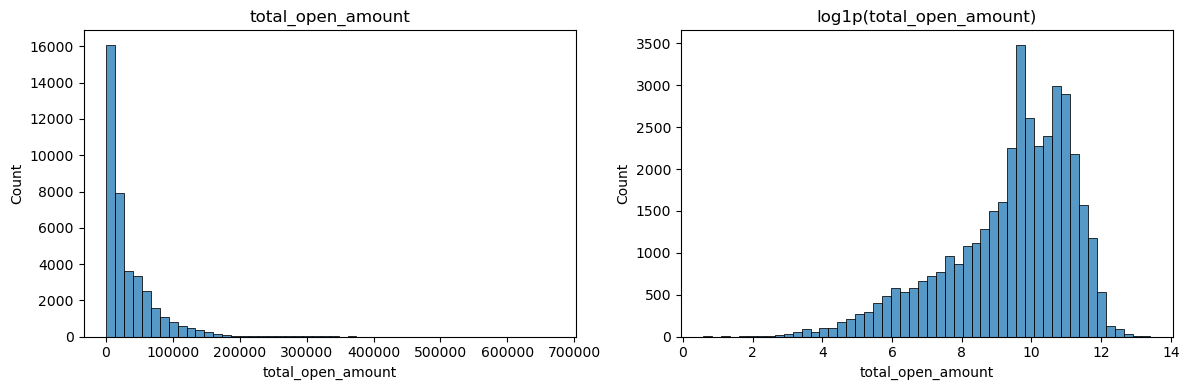

skew raw: 2.76
skew log: -0.97
count     39158.000000
mean      32058.090425
std       39585.535477
min           0.790000
25%        4681.740000
50%       17245.895000
75%       46542.090000
max      668593.360000
Name: total_open_amount, dtype: float64


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

amount = df["total_open_amount"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(amount, bins=50, ax=axes[0])
axes[0].set_title("total_open_amount")

sns.histplot(np.log1p(amount), bins=50, ax=axes[1])
axes[1].set_title("log1p(total_open_amount)")

plt.tight_layout()
plt.show()

print("skew raw:", round(amount.skew(), 2))
print("skew log:", round(np.log1p(amount).skew(), 2))
print(amount.describe())

In [27]:
df["log_amount"] = np.log1p(df["total_open_amount"])

In [28]:
df.head().T

,0,1,2,4,5
business_code,u001,u001,u001,u001,ca02
cust_number,200769623,200980828,200792734,200769623,140106181
name_customer,wal-mar_corp,ben_e_,mdv/_trust,wal-mar_foundation,the__corporation
buisness_year,2020,2019,2019,2019,2019
doc_id,1930438491,1929646410,1929873765,1930147974,2960581231
posting_date,2020-01-26 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2019-11-13 00:00:00,2019-09-20 00:00:00
document_create_date,2020-01-25 00:00:00,2019-07-22 00:00:00,2019-09-14 00:00:00,2019-11-13 00:00:00,2019-09-20 00:00:00
due_in_date,2020-02-10 00:00:00,2019-08-11 00:00:00,2019-09-29 00:00:00,2019-11-28 00:00:00,2019-10-04 00:00:00
invoice_currency,usd,usd,usd,usd,cad
total_open_amount,54273.28,79656.6,2253.86,33133.29,22225.84


### 1.6 Train / validation / test split

Random split: 60% train, 20% validation, 20% test (`random_state=1`). The target `late` is separated from the inputs.

The split is random, not by date, so customers and months appear in all three sets. Section 2.3 compares it with a time-based split.

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [31]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [32]:
len(df_full_train)/len(df), len(df_val)/len(df), len(df_test)/len(df)

(0.7999897849736963, 0.2000102150263037, 0.2000102150263037)

In [33]:
df_full_train.isnull().sum()

business_code           0
cust_number             0
name_customer           0
buisness_year           0
doc_id                  0
posting_date            0
document_create_date    0
due_in_date             0
invoice_currency        0
total_open_amount       0
baseline_create_date    0
cust_payment_terms      0
late                    0
days_allowed            0
days_to_due             0
due_month               0
due_weekday             0
due_on_weekend          0
log_amount              0
dtype: int64

In [34]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [35]:
y_train = df_train.late.values
y_val = df_val.late.values
y_test = df_test.late.values

In [36]:
del df_train['late']
del df_val['late']
del df_test['late']

In [37]:
df_train.columns

Index(['business_code', 'cust_number', 'name_customer', 'buisness_year',
       'doc_id', 'posting_date', 'document_create_date', 'due_in_date',
       'invoice_currency', 'total_open_amount', 'baseline_create_date',
       'cust_payment_terms', 'days_allowed', 'days_to_due', 'due_month',
       'due_weekday', 'due_on_weekend', 'log_amount'],
      dtype='object')

## 2. Logistic regression

### 2.1 Baseline

Numerical features are standardized (scaler fitted on the training set only) and categorical ones are one-hot encoded with `DictVectorizer`. The validation AUC is printed below.

This first run uses the default `LogisticRegression()` and may print a convergence warning (`max_iter=100`). Section 2.2 repeats the model with `solver='liblinear'` and `max_iter=1000`, so its numbers can differ slightly.

In [38]:
# Scale the numbers for a logistic regression (the scaler learns only from the training set):

from sklearn.preprocessing import StandardScaler

numerical   = ["log_amount", "days_allowed", "days_to_due", "due_month", "due_weekday", "due_on_weekend"]
categorical = ["business_code", "invoice_currency", "cust_payment_terms", "cust_number"]

df_train_scaled = df_train.copy()      # copies, so df_train and df_val stay unscaled
df_val_scaled   = df_val.copy()

scaler = StandardScaler()
df_train_scaled[numerical] = scaler.fit_transform(df_train_scaled[numerical])   # learns mean and std from training only
df_val_scaled[numerical]   = scaler.transform(df_val_scaled[numerical])         # applies the same values to validation

In [39]:
from sklearn.feature_extraction import DictVectorizer

In [40]:
dv = DictVectorizer(sparse=False)
from sklearn.linear_model import LogisticRegression

train_dict = df_train_scaled[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

/home/orlando/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [41]:
from sklearn.metrics import roc_auc_score

val_dict = df_val_scaled[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(auc)

0.8460125249605939


### 2.2 Which features help?

The function `run(numerical)` does the same steps as the baseline (scale, one-hot, train, AUC on validation), for any list of numerical features. The calendar features are added one at a time to see whether each improves the validation AUC.

Rule of thumb: keep a feature only if the AUC improves by about 0.005 or more; smaller changes are noise.

In [42]:
# Train and evaluate logistic regression for one list of numerical features
# (same steps as the baseline above: scale, one-hot encoding, fit, AUC on validation).
# By default it uses the random split; another split can be passed in (see the next cells):

def run(numerical, df_train=df_train, df_val=df_val, y_train=y_train, y_val=y_val):
    # copies, so df_train and df_val stay untouched
    df_train_run = df_train.copy()
    df_val_run   = df_val.copy()

    scaler = StandardScaler()
    df_train_run[numerical] = scaler.fit_transform(df_train_run[numerical])
    df_val_run[numerical]   = scaler.transform(df_val_run[numerical])

    dv = DictVectorizer(sparse=False)

    train_dict = df_train_run[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    val_dict = df_val_run[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(val_dict)

    y_pred = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_pred)

In [43]:
base = ["log_amount", "days_allowed", "days_to_due"]

experiments = {
    "base (no calendar features)": base,
    "+ due_on_weekend":            base + ["due_on_weekend"],
    "+ due_weekday":               base + ["due_weekday"],
    "+ due_month":                 base + ["due_month"],
    "all calendar features":       base + ["due_month", "due_weekday", "due_on_weekend"],
}

results = []

for name, features in experiments.items():
    auc = run(features)
    results.append((name, ", ".join(features), round(auc, 4)))
    print(f'{name:30s} AUC = {auc:.4f}')

df_results = pd.DataFrame(results, columns=['experiment', 'numerical features', 'validation AUC'])
df_results

base (no calendar features)    AUC = 0.8131
+ due_on_weekend               AUC = 0.8443
+ due_weekday                  AUC = 0.8258
+ due_month                    AUC = 0.8131
all calendar features          AUC = 0.8463


,experiment,numerical features,validation AUC
0,base (no calendar features),"log_amount, days_allowed, days_to_due",0.8131
1,+ due_on_weekend,"log_amount, days_allowed, days_to_due, due_on_...",0.8443
2,+ due_weekday,"log_amount, days_allowed, days_to_due, due_wee...",0.8258
3,+ due_month,"log_amount, days_allowed, days_to_due, due_month",0.8131
4,all calendar features,"log_amount, days_allowed, days_to_due, due_mon...",0.8463


### 2.3 Random vs time-based split

A random split assumes every invoice is an independent draw from the same process. Here invoices come in time order and the model will be used on *future* invoices, so the stricter test is: train on the oldest 60%, validate on the next 20%, test on the newest 20% (by `posting_date`). If both splits give similar AUC, the random split is acceptable.

In [44]:
# Time-based split: oldest 60% to train, next 20% validation, newest 20% test (by posting date)

df_sorted = df.sort_values('posting_date').reset_index(drop=True)
n = len(df_sorted)
n_train, n_val = int(n * 0.6), int(n * 0.2)

df_train_t = df_sorted.iloc[:n_train].copy()
df_val_t   = df_sorted.iloc[n_train:n_train + n_val].copy()
df_test_t  = df_sorted.iloc[n_train + n_val:].copy()

y_train_t = df_train_t.late.values
y_val_t   = df_val_t.late.values
y_test_t  = df_test_t.late.values

del df_train_t['late']
del df_val_t['late']
del df_test_t['late']

print('train:', df_train_t.posting_date.min().date(), '->', df_train_t.posting_date.max().date())
print('valid:', df_val_t.posting_date.min().date(), '->', df_val_t.posting_date.max().date())
print('test: ', df_test_t.posting_date.min().date(), '->', df_test_t.posting_date.max().date())
print('late rate train / val / test:', y_train_t.mean().round(3), y_val_t.mean().round(3), y_test_t.mean().round(3))

train: 2018-12-30 -> 2019-08-29
valid: 2019-08-29 -> 2019-11-19
test:  2019-11-19 -> 2020-02-27
late rate train / val / test: 0.426 0.427 0.392


In [45]:
# Same experiments on both splits:

results_split = []

for name, features in experiments.items():
    auc_random = run(features)
    auc_time   = run(features, df_train_t, df_val_t, y_train_t, y_val_t)
    results_split.append((name, round(auc_random, 4), round(auc_time, 4)))

df_results_split = pd.DataFrame(results_split, columns=['experiment', 'AUC random split', 'AUC time split'])
df_results_split

,experiment,AUC random split,AUC time split
0,base (no calendar features),0.8131,0.8081
1,+ due_on_weekend,0.8443,0.8382
2,+ due_weekday,0.8258,0.8189
3,+ due_month,0.8131,0.8079
4,all calendar features,0.8463,0.8403


### 2.4 Result

- The best logistic regression uses the base features plus all calendar features (validation AUC about 0.846). `due_on_weekend` gives the biggest gain; `due_month` adds nothing alone.
- The time-based split is only about 0.006 lower than the random split, so the random split is kept for the rest of the notebook.
- The same feature set (`categorical + numerical`) is used for the tree models below.

## 3. Random forest

### 3.1 Matrices for the tree models

Trees do not need scaling, so the matrices are built again from the **unscaled** `df_train`, `df_val` and `df_test`, with a `DictVectorizer` fitted on the training set only. The same `X_train`, `X_val` and `X_test` are used for the decision tree, the random forest and XGBoost.

In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts   = df_val[categorical + numerical].to_dict(orient='records')
test_dicts  = df_test[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)   # fitted on the training set only
X_val   = dv.transform(val_dicts)
X_test  = dv.transform(test_dicts)        # used only in section 5

X_train.shape, X_val.shape, X_test.shape

((23494, 958), (7832, 958), (7832, 958))

### 3.2 Decision tree

A single tree with default settings, as a reference. Without limits it grows until it memorizes the training set, so the validation AUC is low.

In [47]:
dt = DecisionTreeClassifier(random_state=1)
dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [48]:
y_pred = dt.predict_proba(X_val)[:,1]
roc_auc_score(y_val, y_pred)

0.7495662459964814

### 3.3 Decision tree tuning

First `max_depth` alone, then `max_depth` together with `min_samples_leaf`.

In [49]:
for d in [1, 2, 3, 4, 5, 6, 10, 12, 15, 17, 20, 25, 30, 35, 40, None]:
    dt = DecisionTreeClassifier(max_depth=d, random_state=1)
    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('depth = %4s: %.3f' % (d, auc))

depth =    1: 0.618
depth =    2: 0.697
depth =    3: 0.734
depth =    4: 0.751
depth =    5: 0.756
depth =    6: 0.767
depth =   10: 0.790
depth =   12: 0.788
depth =   15: 0.789
depth =   17: 0.786
depth =   20: 0.776
depth =   25: 0.768
depth =   30: 0.762
depth =   35: 0.760
depth =   40: 0.758
depth = None: 0.750


In [50]:
scores = []
max_auc = 0

for md in [10, 15, 20, 25]:
    for msl in [1, 5, 10, 15, 20, 100, 200, 500]:
        dt = DecisionTreeClassifier(max_depth=md, min_samples_leaf=msl, random_state=1)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)

        if auc > max_auc:
            print(f'auc = {auc:.3f}: max_depth = {md:.3g} and min_samples_leaf = {msl:.3g}')
            max_auc = auc

        scores.append((md, msl, auc))
        

auc = 0.790: max_depth = 10 and min_samples_leaf = 1
auc = 0.794: max_depth = 10 and min_samples_leaf = 5
auc = 0.803: max_depth = 15 and min_samples_leaf = 5
auc = 0.808: max_depth = 15 and min_samples_leaf = 10
auc = 0.811: max_depth = 15 and min_samples_leaf = 15
auc = 0.811: max_depth = 15 and min_samples_leaf = 20
auc = 0.817: max_depth = 20 and min_samples_leaf = 10
auc = 0.819: max_depth = 20 and min_samples_leaf = 15
auc = 0.822: max_depth = 25 and min_samples_leaf = 10
auc = 0.825: max_depth = 25 and min_samples_leaf = 15


In [51]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores = df_scores.sort_values(by='auc', ascending=False)
df_scores.head()

,max_depth,min_samples_leaf,auc
27,25,15,0.824746
28,25,20,0.823671
26,25,10,0.822482
19,20,15,0.819196
20,20,20,0.818318


In [52]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf',columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                     
max_depth            10     15     20     25
min_samples_leaf                            
1                 0.790  0.789  0.776  0.768
5                 0.794  0.803  0.809  0.811
10                0.793  0.808  0.817  0.822
15                0.792  0.811  0.819  0.825
20                0.793  0.811  0.818  0.824
100               0.790  0.805  0.806  0.805
200               0.783  0.795  0.795  0.795
500               0.767  0.768  0.768  0.768

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

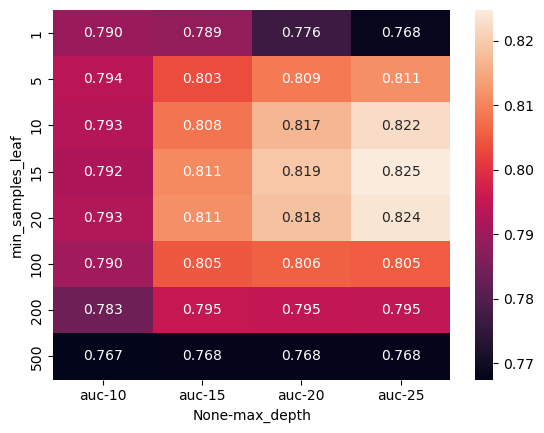

In [53]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [54]:
dt = DecisionTreeClassifier(max_depth=25, min_samples_leaf=15, random_state=1)
dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_val)[:, 1]
auc_dt = roc_auc_score(y_val, y_pred)
print('tuned decision tree, validation AUC = %.4f' % auc_dt)

tuned decision tree, validation AUC = 0.8247


### 3.4 Random forest

A first forest with 10 trees and default settings.

In [55]:
rf = RandomForestClassifier(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]
round(roc_auc_score(y_val, y_pred), 3)

0.842

### 3.5 Random forest tuning

`max_depth` and the number of trees first, then `min_samples_leaf`. (`n_jobs=-1` only uses all processor cores; it does not change the results.)

In [56]:
scores = []

for d in [25, 30, 35, 40, 45]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1,
                                    n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

In [57]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

Text(0, 0.5, 'auc')

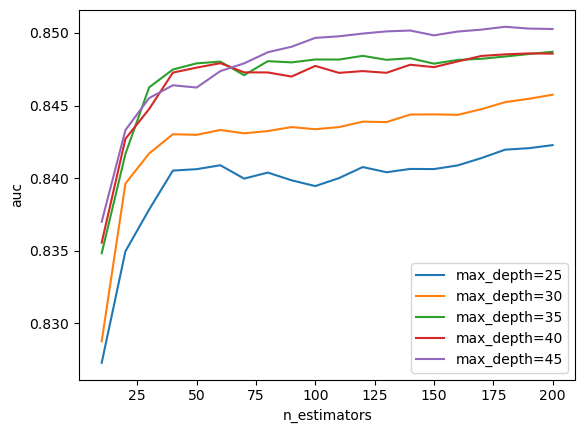

In [58]:
for d in [25, 30, 35, 40, 45]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()
plt.xlabel('n_estimators')
plt.ylabel('auc')

In [59]:
max_depth = 45

In [60]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1,
                                    n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

In [61]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

Text(0, 0.5, 'auc')

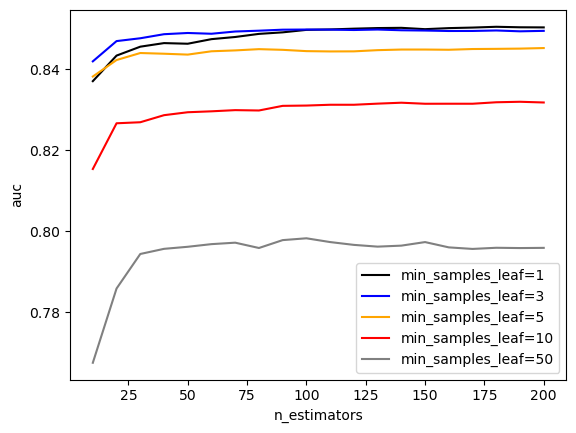

In [62]:
colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    
    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()
plt.xlabel('n_estimators')
plt.ylabel('auc')

In [63]:
min_samples_leaf = 3

### 3.6 Result

The tuned random forest, evaluated on the **validation** set.

In [64]:
rf = RandomForestClassifier(n_estimators=175,
                            max_depth=45,
                            min_samples_leaf=3,
                            random_state=1,
                            n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]
auc_rf = roc_auc_score(y_val, y_pred)
print('tuned random forest, validation AUC = %.4f' % auc_rf)

tuned random forest, validation AUC = 0.8494


## 4. XGBoost

### 4.1 First model

Same matrices as the random forest (section 3.1), wrapped in `DMatrix`.

In [65]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval   = xgb.DMatrix(X_val,   label=y_val,   feature_names=features)

xgb_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200)

y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.854777530654997

### 4.2 Tuning

One parameter at a time, as in the course: `eta`, then `max_depth`, then `min_child_weight`. Each run prints the train and validation AUC every 5 rounds; `parse_xgb_output` turns that text into a table for the plots.

In [66]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        
        it, train, val = line.split('\t')
        it = int(it.strip('[]'))
        train = float(train.strip('train-auc:'))
        val = float(val.strip('val-auc:'))
        
        results.append((it, train, val))
        
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [67]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

**`eta`** (learning rate)

In [68]:
scores = {}

In [69]:
%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [70]:
scores['eta: 0.1'] = parse_xgb_output(output)

In [71]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [72]:
scores['eta: 0.3'] = parse_xgb_output(output)

In [73]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [74]:
scores['eta: 0.5'] = parse_xgb_output(output)

In [75]:
%%capture output

xgb_params = {
    'eta': 0.7,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [76]:
scores['eta: 0.7'] = parse_xgb_output(output)

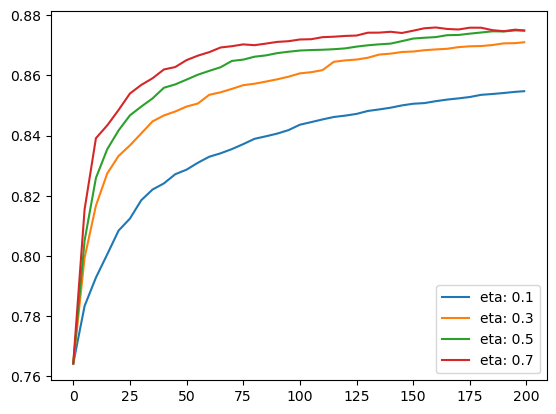

In [77]:
for eta, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=eta)

plt.legend()

**`max_depth`** (with `eta = 0.5`)

In [78]:
scores = {}

In [79]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 2,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [80]:
scores['max_depth: 2'] = parse_xgb_output(output)

In [81]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [82]:
scores['max_depth: 3'] = parse_xgb_output(output)

In [83]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 5,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [84]:
scores['max_depth: 5'] = parse_xgb_output(output)

In [85]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 7,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [86]:
scores['max_depth: 7'] = parse_xgb_output(output)

In [87]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 9,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [88]:
scores['max_depth: 9'] = parse_xgb_output(output)

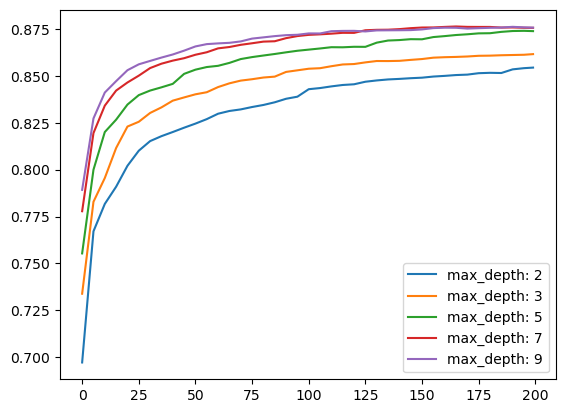

In [89]:
for name, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=name)

plt.legend()

**`min_child_weight`** (with `eta = 0.5`, `max_depth = 7`)

In [90]:
scores = {}

In [91]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 7,
    'min_child_weight': 2,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [92]:
scores['min_child_weight: 2'] = parse_xgb_output(output)

In [93]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 7,
    'min_child_weight': 3,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [94]:
scores['min_child_weight: 3'] = parse_xgb_output(output)

In [95]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 7,
    'min_child_weight': 5,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [96]:
scores['min_child_weight: 5'] = parse_xgb_output(output)

In [97]:
%%capture output

xgb_params = {
    'eta': 0.5,
    'max_depth': 7,
    'min_child_weight': 30,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval=5, evals=watchlist)

In [98]:
scores['min_child_weight: 30'] = parse_xgb_output(output)

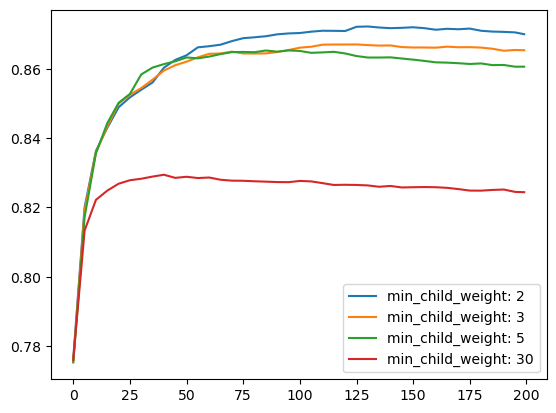

In [99]:
for min_child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=min_child_weight)

plt.legend()

### 4.3 Result

The tuned XGBoost (`eta = 0.5`, `max_depth = 7`, `min_child_weight = 2`, 200 rounds), evaluated on the **validation** set.

In [100]:
xgb_params = {
    'eta': 0.5,
    'max_depth': 7,
    'min_child_weight': 2,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model_xgb = xgb.train(xgb_params, dtrain, num_boost_round=200)

y_pred = model_xgb.predict(dval)
auc_xgb = roc_auc_score(y_val, y_pred)
print('tuned XGBoost, validation AUC = %.4f' % auc_xgb)

tuned XGBoost, validation AUC = 0.8700


## 5. Final test

### 5.1 Comparison of the three models

The final model is chosen by the **validation** AUC. The test AUC is shown next to it only as a check that the validation numbers were not optimistic; it is not used to choose.

All three models here are trained on the training set (60%) with the same features.

In [101]:
# Logistic regression (best feature set from section 2): scaled copies of train, validation and test

df_train_lr = df_train.copy()
df_val_lr   = df_val.copy()
df_test_lr  = df_test.copy()

scaler = StandardScaler()
df_train_lr[numerical] = scaler.fit_transform(df_train_lr[numerical])
df_val_lr[numerical]   = scaler.transform(df_val_lr[numerical])
df_test_lr[numerical]  = scaler.transform(df_test_lr[numerical])

dv_lr = DictVectorizer(sparse=False)
X_train_lr = dv_lr.fit_transform(df_train_lr[categorical + numerical].to_dict(orient='records'))
X_val_lr   = dv_lr.transform(df_val_lr[categorical + numerical].to_dict(orient='records'))
X_test_lr  = dv_lr.transform(df_test_lr[categorical + numerical].to_dict(orient='records'))

model_lr = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model_lr.fit(X_train_lr, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


In [102]:
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=features)

comparison = [
    ('Logistic regression',
     roc_auc_score(y_val,  model_lr.predict_proba(X_val_lr)[:, 1]),
     roc_auc_score(y_test, model_lr.predict_proba(X_test_lr)[:, 1])),
    ('Random forest (175 trees, max_depth 45, min_samples_leaf 3)',
     roc_auc_score(y_val,  rf.predict_proba(X_val)[:, 1]),
     roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])),
    ('XGBoost (eta 0.5, max_depth 7, min_child_weight 2, 200 rounds)',
     roc_auc_score(y_val,  model_xgb.predict(dval)),
     roc_auc_score(y_test, model_xgb.predict(dtest))),
]

df_comparison = pd.DataFrame(comparison, columns=['model', 'validation AUC', 'test AUC']).round(4)
df_comparison

,model,validation AUC,test AUC
0,Logistic regression,0.8463,0.8439
1,"Random forest (175 trees, max_depth 45, min_sa...",0.8494,0.8533
2,"XGBoost (eta 0.5, max_depth 7, min_child_weigh...",0.8700,0.8747


### 5.2 Final model

XGBoost has the best validation AUC, so it is the final model. It is trained again on train + validation (80% of the data) and evaluated once on the test set. This is the model that `train.py` saves.

In [103]:
df_full_train = df_full_train.reset_index(drop=True)
y_full_train  = df_full_train.late.values

full_train_dicts = df_full_train[categorical + numerical].to_dict(orient='records')

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(full_train_dicts)
X_test_final = dv_final.transform(test_dicts)

features_final = list(dv_final.get_feature_names_out())

dfull_train = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features_final)
dtest_final = xgb.DMatrix(X_test_final, label=y_test,       feature_names=features_final)

model_final = xgb.train(xgb_params, dfull_train, num_boost_round=200)

y_pred = model_final.predict(dtest_final)
auc_final = roc_auc_score(y_test, y_pred)
print('final model (XGBoost, train + validation): test AUC = %.4f' % auc_final)

final model (XGBoost, train + validation): test AUC = 0.8840
